Libraries & Parameters

In [2]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import numpy as np
import os
import cv2

CLASSES = ['glioma', 'meningioma', 'notumor', 'pituitary']
IMG_SIZE = 224
BATCH_SIZE = 32

DATASET_PATH = 'dataset'
IMAGE_FOLDER = 'images'

Data Loader

In [3]:
train_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    os.path.join(DATASET_PATH, 'Training'),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

validation_generator = test_datagen.flow_from_directory(
    os.path.join(DATASET_PATH, 'Testing'),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

Found 8582 images belonging to 4 classes.
Found 1705 images belonging to 4 classes.


Feature Extraction

In [4]:
def build_proposed_model():
    model = models.Sequential([
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
        layers.MaxPooling2D((2, 2)), 
        
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(len(CLASSES), activation='softmax')
    ])
    
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

model = build_proposed_model()

C:\Users\canat\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Modal Training

In [5]:
history = model.fit(
    train_generator,
    epochs=15, 
    validation_data=validation_generator
)

Epoch 1/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 127s 465ms/step - accuracy: 0.7439 - loss: 0.6560 - val_accuracy: 0.7918 - val_loss: 0.7966
Epoch 2/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 83s 308ms/step - accuracy: 0.8829 - loss: 0.3086 - val_accuracy: 0.8645 - val_loss: 0.8100
Epoch 3/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 81s 302ms/step - accuracy: 0.9349 - loss: 0.1778 - val_accuracy: 0.8792 - val_loss: 0.8580
Epoch 4/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 81s 302ms/step - accuracy: 0.9544 - loss: 0.1269 - val_accuracy: 0.9097 - val_loss: 0.6966
Epoch 5/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 80s 298ms/step - accuracy: 0.9723 - loss: 0.0853 - val_accuracy: 0.9038 - val_loss: 0.6719
Epoch 6/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 80s 298ms/step - accuracy: 0.9786 - loss: 0.0608 - val_accuracy: 0.9056 - val_loss: 1.0095
Epoch 7/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 81s 301ms/step - accuracy: 0.9803 - loss: 0.0600 - val_accuracy: 0.9196 - val_loss: 0.9913
Epoch 8/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 85s 316ms/step - accuracy: 0.9869 - loss: 

Final Prediction

In [6]:
def run_final_inference():
    """
    Performs prediction on the local 'images' folder and 
    prints results in English academic format.
    """
    print(f"{'Filename':<25} | {'Prediction':<15} | {'Confidence'}")
    print("-" * 60)
    
    for filename in os.listdir(IMAGE_FOLDER):
        if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
            path = os.path.join(IMAGE_FOLDER, filename)
            
            img = cv2.imread(path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
            img = img / 255.0
            img = np.expand_dims(img, axis=0)
            
            preds = model.predict(img, verbose=0)
            idx = np.argmax(preds)
            conf = np.max(preds) * 100
            
            print(f"{filename:<25} | {CLASSES[idx]:<15} | {conf:.2f}%")

run_final_inference()

Filename                  | Prediction      | Confidence
------------------------------------------------------------
Hirnmetastase_MRT-T1_KM.jpg | meningioma      | 95.13%


Plotting Training History

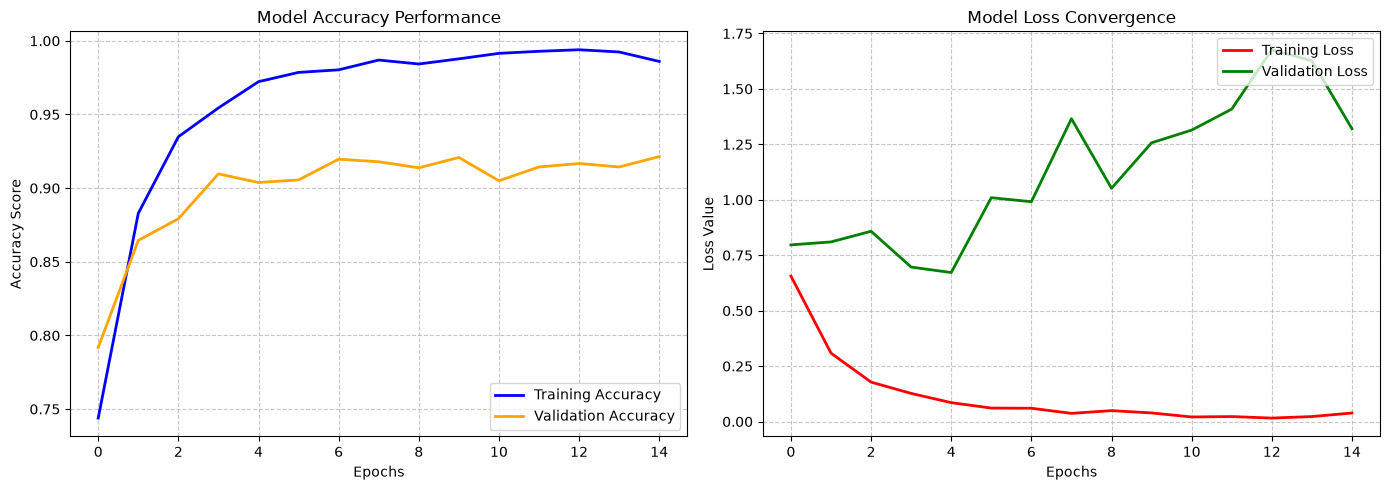

In [7]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy', color='blue', lw=2)
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange', lw=2)
plt.title('Model Accuracy Performance')
plt.xlabel('Epochs')
plt.ylabel('Accuracy Score')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.7)

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss', color='red', lw=2)
plt.plot(history.history['val_loss'], label='Validation Loss', color='green', lw=2)
plt.title('Model Loss Convergence')
plt.xlabel('Epochs')
plt.ylabel('Loss Value')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Confusion Matrix & Classification Report

Generating evaluation metrics...
Found 1705 images belonging to 4 classes.
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 88ms/step


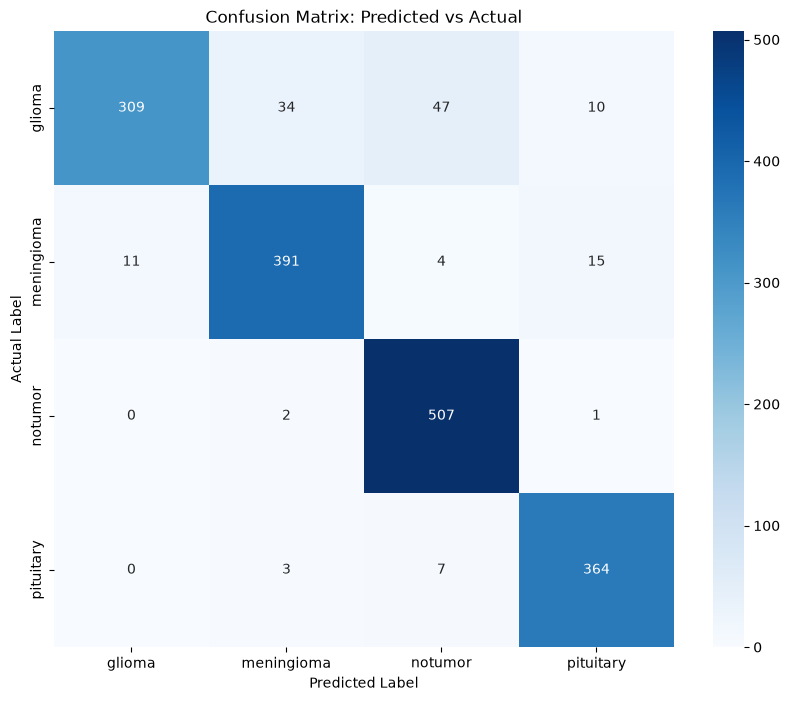


Classification Report:
              precision    recall  f1-score   support

      glioma       0.97      0.77      0.86       400
  meningioma       0.91      0.93      0.92       421
     notumor       0.90      0.99      0.94       510
   pituitary       0.93      0.97      0.95       374

    accuracy                           0.92      1705
   macro avg       0.93      0.92      0.92      1705
weighted avg       0.92      0.92      0.92      1705



In [10]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

print("Generating evaluation metrics...")
# shuffle=False keeps predictions in the same order as eval_generator.classes
eval_generator = test_datagen.flow_from_directory(
    os.path.join(DATASET_PATH, 'Testing'),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)
Y_pred = model.predict(eval_generator)
y_pred = np.argmax(Y_pred, axis=1)
y_true = eval_generator.classes

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.title('Confusion Matrix: Predicted vs Actual')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=CLASSES))

Visualizing Predictions with a Grid

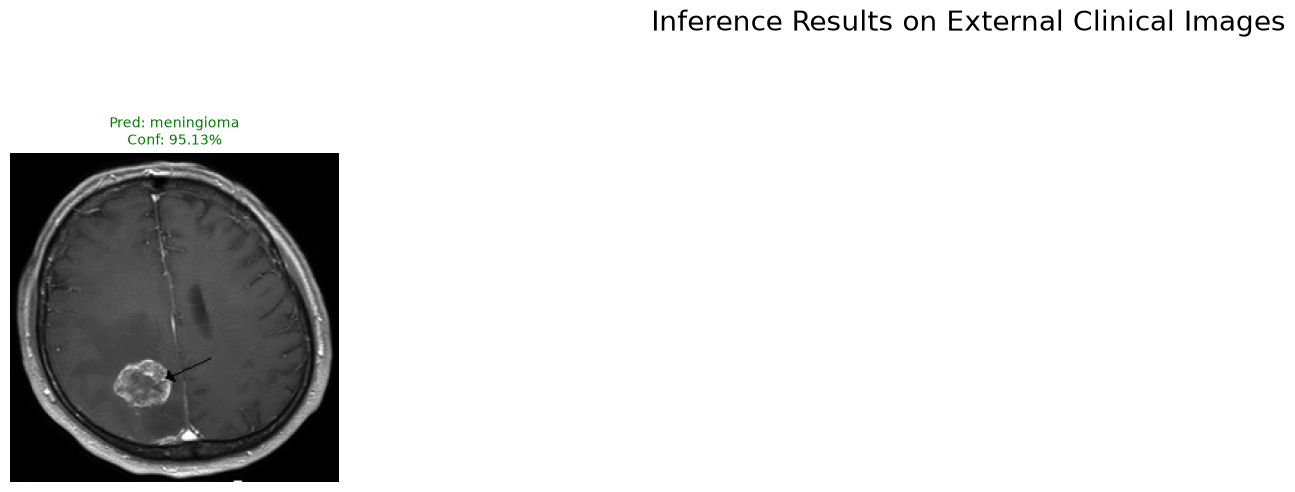

In [11]:
import matplotlib.pyplot as plt

def visualize_test_results(folder_path, grid_rows=4, grid_cols=5):
    file_list = [f for f in os.listdir(folder_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    plt.figure(figsize=(20, 16))
    
    for i, filename in enumerate(file_list[:20]):
        path = os.path.join(folder_path, filename)
        
        raw_img = cv2.imread(path)
        img_rgb = cv2.cvtColor(raw_img, cv2.COLOR_BGR2RGB)
        img_resized = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE))
        img_norm = img_resized / 255.0
        img_input = np.expand_dims(img_norm, axis=0)
        
        preds = model.predict(img_input, verbose=0)
        idx = np.argmax(preds)
        conf = np.max(preds) * 100
        
        plt.subplot(grid_rows, grid_cols, i + 1)
        plt.imshow(img_resized)
        
        title_color = 'green' if conf > 80 else 'orange'
        plt.title(f"Pred: {CLASSES[idx]}\nConf: {conf:.2f}%", color=title_color, fontsize=10)
        plt.axis('off')

    plt.suptitle("Inference Results on External Clinical Images", fontsize=20)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

visualize_test_results(IMAGE_FOLDER)

Save Modal

In [12]:
model.save('brain_tumor_expert_model.keras')
print("Model saved successfully as .keras file!")

Model saved successfully as .keras file!
